In [ ]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [44]:
from pathlib import Path

# you guys can change the path if it
ROOT = Path("/content/drive/MyDrive/DIOR")

In [45]:
import zipfile

LOCAL_ROOT = Path("/content/DIOR")
LOCAL_ROOT.mkdir(exist_ok=True)

zips = [
    ("ImageSets.zip", LOCAL_ROOT),
    ("JPEGImages-trainval.zip", LOCAL_ROOT),
    ("JPEGImages-test.zip", LOCAL_ROOT),
    ("Annotations.zip", LOCAL_ROOT)
]

# extract zip files
for zip_name, dest in zips:
    zip_path = ROOT / zip_name
    if zip_path.exists():
        print(f"Extracting {zip_name} to {dest}...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(dest)
        print(f"Finished extracting {zip_name}.")
    else:
        print(f"Could not find {zip_path}")

Extracting ImageSets.zip to /content/DIOR...
Finished extracting ImageSets.zip.
Extracting JPEGImages-trainval.zip to /content/DIOR...
Finished extracting JPEGImages-trainval.zip.
Extracting JPEGImages-test.zip to /content/DIOR...
Finished extracting JPEGImages-test.zip.
Extracting Annotations.zip to /content/DIOR...
Finished extracting Annotations.zip.


In [47]:
TRAIN_IMAGES = LOCAL_ROOT / "JPEGImages-trainval"
TEST_IMAGES = LOCAL_ROOT / "JPEGImages-test"
ANNOTATIONS = LOCAL_ROOT / "Annotations/Horizontal Bounding Boxes"
SPLITS = LOCAL_ROOT / "Main"

for path in ROOT.iterdir():
    print(path.name)


ImageSets.zip
JPEGImages-trainval.zip
JPEGImages-test.zip
Annotations.zip


In [48]:
# count images and annotations from datatset
from collections import Counter
import xml.etree.ElementTree as ET

train_images = list(TRAIN_IMAGES.glob("*.jpg"))
test_images = list(TEST_IMAGES.glob("*.jpg"))
xml_files = list(ANNOTATIONS.glob("*.xml"))

print("Train/val images:", len(train_images))
print("Test images:", len(test_images))
print("Total images:", len(train_images) + len(test_images))
print("Available XML files:", len(xml_files))

counts = Counter()

for xml_path in xml_files:
    root = ET.parse(xml_path).getroot()
    for obj in root.findall("object"):
        counts[obj.findtext("name")] += 1

print("Annotated objects available:", sum(counts.values()))
print("Distinct class labels:", len(counts))
print(counts)


Train/val images: 11725
Test images: 11738
Total images: 23463
Available XML files: 23463
Annotated objects available: 192518
Distinct class labels: 20
Counter({'ship': 62537, 'vehicle': 40365, 'storagetank': 26403, 'tenniscourt': 12241, 'airplane': 10100, 'baseballfield': 5818, 'harbor': 5469, 'windmill': 5363, 'bridge': 3956, 'basketballcourt': 3223, 'overpass': 3112, 'groundtrackfield': 3047, 'Expressway-Service-area': 2165, 'chimney': 1680, 'airport': 1328, 'Expressway-toll-station': 1298, 'stadium': 1267, 'golffield': 1086, 'dam': 1050, 'trainstation': 1010})


In [49]:
def read(filename):
    return (SPLITS / filename).read_text().splitlines()

train_ids = read("train.txt")
val_ids = read("val.txt")
test_ids = read("test.txt")

trainval_ids = train_ids + val_ids

print("Train:", len(train_ids))
print("Val:", len(val_ids))
print("Trainval:", len(trainval_ids))
print("Test:", len(test_ids))

assert set(train_ids).isdisjoint(val_ids)
assert set(trainval_ids).isdisjoint(test_ids)
assert len(trainval_ids) == 11725
assert len(test_ids) == 11738


Train: 5862
Val: 5863
Trainval: 11725
Test: 11738


In [ ]:
# test reader

In [51]:
from dataset import DIORDataset, collate_fn, CLASS_NAMES
from torch.utils.data import DataLoader

LOCAL_ROOT = Path("/content/DIOR")
train_dataset = DIORDataset(LOCAL_ROOT, split="train")

print("Dataset size:", len(train_dataset))

image, target = train_dataset[0]

print("Image:", image.shape)
print("Boxes:", target["boxes"].shape)
print("Labels:", target["labels"])

loader = DataLoader(
    train_dataset,
    batch_size=2,
    shuffle=True,
    collate_fn=collate_fn,
    num_workers=0
)

images, targets = next(iter(loader))
print("Batch size:", len(images))

Dataset size: 5862
Image: torch.Size([3, 800, 800])
Boxes: torch.Size([1, 4])
Labels: tensor([10])
Batch size: 2


In [52]:
# manually check 20 images
import random
import matplotlib.pyplot as plt
import matplotlib.patches as patches

# save to outputs/
OUTPUT = Path("outputs/ground_truth")
OUTPUT.mkdir(parents=True, exist_ok=True)

random.seed(174)

# randomly select 20 images from training DS
selected = random.sample(
    range(len(train_dataset)), 20
)

# load each image and annotation
for i, idx in enumerate(selected):
    image, target = train_dataset[idx]

    fig, ax = plt.subplots(figsize=(8, 8))
    ax.imshow(image.permute(1, 2, 0))

    # draw bounding boxes and save with object class name
    for box, label in zip(
        target["boxes"], target["labels"]
    ):
        x1, y1, x2, y2 = box.tolist()
        class_name = CLASS_NAMES[label.item() - 1]

        rect = patches.Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="red",
            facecolor="none"
        )

        ax.add_patch(rect)
        ax.text(
            x1, y1, class_name,
            color="white",
            bbox={"facecolor": "red"}
        )

    ax.axis("off")
    fig.savefig(
        OUTPUT / f"example_{i+1:02}.png",
        bbox_inches="tight"
    )
    plt.close(fig)


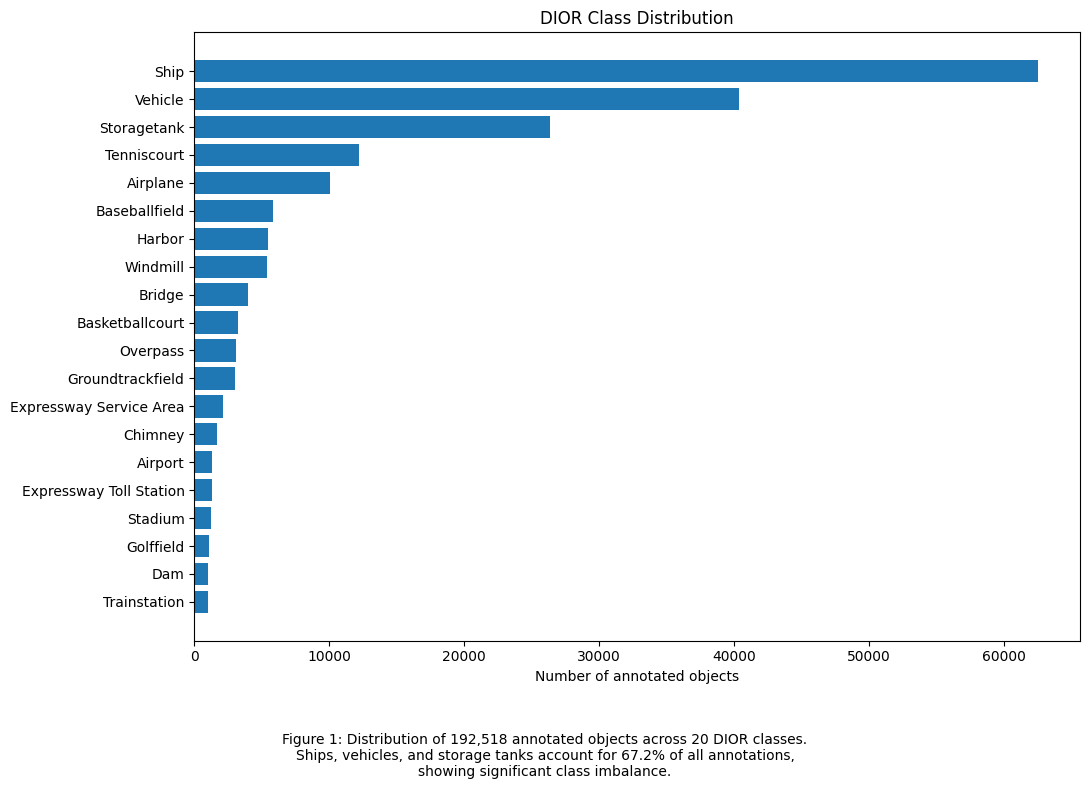

In [53]:

import matplotlib.pyplot as plt

sorted_counts = counts.most_common()

names = [
    name.replace("-", " ").title()
    for name, count in sorted_counts
]
values = [count for name, count in sorted_counts]

fig, ax = plt.subplots(figsize=(11, 8))

ax.barh(names, values)
ax.invert_yaxis()

ax.set_xlabel("Number of annotated objects")
ax.set_title("DIOR Class Distribution")

caption = (
    "Figure 1: Distribution of 192,518 annotated objects across "
    "20 DIOR classes.\nShips, vehicles, and storage tanks account "
    "for 67.2% of all annotations,\nshowing significant class imbalance."
)

fig.text(
    0.5, 0.02, caption,
    ha="center",
    va="bottom",
    fontsize=10
)

plt.tight_layout(rect=[0, 0.12, 1, 1])
plt.savefig(
    "outputs/class_distribution.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()
